# FoodSphere AI — Feature 2: Finding the right organization for the food

> ⚠️ **This notebook uses a SYNTHETIC dataset.** No public dataset records which organizations accepted/received surplus-food
> donations, so `generate_matching_dataset.py` simulates realistic offers (anchored on the Kaggle food-waste data, real Dhaka
> areas, fictional organization names). Every row has `Data_Source = synthetic`. The scores below show that the **pipeline works**;
> they are **not** real-world accuracy. The app records real outcomes so the model can be re-trained on real data later.

**Question the model answers:** *“If we offer this donation to this organization, will it be successfully received?”* (Yes/No)
The app first removes unsafe/impossible matches with **rules**, then ranks the remaining organizations by this **predicted success probability**.

In [1]:
import json, warnings, time
import numpy as np, pandas as pd
import matplotlib; matplotlib.use('Agg')
import matplotlib.pyplot as plt, seaborn as sns
from IPython.display import Image, display
from sklearn.base import clone
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.decomposition import PCA
from sklearn.feature_selection import mutual_info_classif
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report,
                             roc_auc_score, roc_curve, ConfusionMatrixDisplay)
from imblearn.over_sampling import SMOTE
import pipeline as P
warnings.filterwarnings('ignore'); pd.set_option('display.width', 160); pd.set_option('display.max_columns', 40)
sns.set_theme(style='whitegrid', palette=['#16804a', '#c97a0a', '#2f7fc4', '#7a5195', '#b42318'])
RS = 42
import os; os.makedirs('reports', exist_ok=True); os.makedirs('data/processed', exist_ok=True)
def save(fig, name):
    fig.tight_layout(); fig.savefig(f'reports/{name}.png', dpi=130); plt.close(fig); display(Image(f'reports/{name}.png'))

## 1. Data collection / loading

In [2]:
raw = P.load_raw(); print(raw.shape); raw.head(3).T

(12424, 29)


,0,1,2
Data_Source,synthetic,synthetic,synthetic
Match_ID,MAT000001,MAT000002,MAT000003
Donation_ID,DON01781,DON01781,DON01781
Org_ID,ORG041,ORG060,ORG051
Date,2025-01-01,2025-01-01,2025-01-01
Time_Posted,16:15,16:15,16:15
Day_of_Week,Wednesday,Wednesday,Wednesday
Business_Type,Restaurant,Restaurant,Restaurant
Food_Category,Dairy,Dairy,Dairy
Quantity_Units,10,10,10


In [3]:
pd.read_csv('data/synthetic_matching_data_dictionary.csv')

,Column,Data_Type,Description,Role,Missing_Pct
0,Data_Source,string,Always 'synthetic' — this dataset is simulated...,info,0.0
1,Match_ID,string,Unique id of one donation offered to one organ...,id,0.0
2,Donation_ID,string,Donation identifier; one donation is offered t...,id,0.0
3,Org_ID,string,Organization identifier (fictional organization).,id,0.0
4,Date,string (date),Date the donation was posted. Mixed formats YY...,feature (day of week),0.0
5,Time_Posted,string (time),Time posted. Mixed formats HH:MM and hh:mm AM/PM.,feature (hour),0.0
6,Day_of_Week,categorical,Weekday of the donation.,feature,0.0
7,Business_Type,categorical,Donor business type (from the Kaggle dataset):...,feature,0.0
8,Food_Category,categorical,"Fruits, Vegetables, Dairy, Bakery, Meat, Prepa...",feature,0.0
9,Quantity_Units,integer,Units offered (sampled from Kaggle leftover st...,feature,0.0


## 2. Exploratory data analysis

In [4]:
info = pd.DataFrame({'missing': raw.isna().sum(), 'missing_%': (raw.isna().mean()*100).round(2), 'unique': raw.nunique()})
print('Exact duplicate rows:', raw.duplicated().sum())
info[info.missing > 0]

Exact duplicate rows: 123


,missing,missing_%,unique
Hours_To_Expiry,232,1.87,962
Storage_Required,267,2.15,6
Org_Type,147,1.18,10
Capacity_Remaining_Units,307,2.47,458
Past_Acceptance_Rate,356,2.87,99
Distance_km,383,3.08,1619
Est_Travel_Time_min,252,2.03,676
Failure_Reason,5000,40.24,10


In [5]:
for c in ['Storage_Required', 'Successful_Match', 'Accepts_Category', 'Food_Category', 'Org_Type']:
    print(c, raw[c].value_counts(dropna=False).to_dict())
print('Non-numeric distances, e.g.:', raw.Distance_km[raw.Distance_km.str.contains('km', na=False)].head(3).tolist())
print('Date formats, e.g.:', raw.Date[raw.Date.str.contains('/', na=False)].head(2).tolist(), '| Time formats, e.g.:', raw.Time_Posted[raw.Time_Posted.str.contains('M', na=False)].head(2).tolist())

Storage_Required {'Ambient': 5520, 'Refrigerated': 5287, 'Frozen': 593, 'Room Temp': 369, 'refrigerated': 348, nan: 267, 'Freezer': 40}
Successful_Match {'No': 7101, 'Yes': 4875, 'N': 269, 'yes': 179}
Accepts_Category {'Yes': 7807, 'No': 4088, 'Y': 317, 'no': 212}
Food_Category {'Prepared Food': 2503, 'Vegetables': 2131, 'Fruits': 2075, 'Bakery': 1837, 'Meat': 1784, 'Dairy': 1742, 'PREPARED FOOD': 77, 'BAKERY': 62, 'VEGETABLES': 62, 'FRUITS': 57, 'MEAT': 50, 'DAIRY': 44}
Org_Type {'Community Kitchen': 3899, 'NGO': 3411, 'Shelter': 1715, 'Orphanage': 1574, 'Food Bank': 1313, nan: 147, 'community kitchen ': 133, 'ngo ': 104, 'shelter ': 58, 'orphanage ': 36, 'food bank ': 34}
Non-numeric distances, e.g.: ['3.75 km', '6.36 km', '3.7 km']
Date formats, e.g.: ['01/01/2025', '01/01/2025'] | Time formats, e.g.: ['06:30 PM', '07:15 PM']


## 3. Data-leakage check
`Accepted`, `Delivered_Quantity` and `Failure_Reason` are only known **after** the offer — using them would be cheating. IDs, names and areas identify rows rather than describe the match (distance already captures location), so they are dropped too.

In [6]:
print('Leakage columns:', P.LEAKAGE_COLUMNS); print('Identifier / proxy columns dropped:', P.DROP_COLUMNS)

Leakage columns: ['Accepted', 'Delivered_Quantity', 'Failure_Reason']
Identifier / proxy columns dropped: ['Data_Source', 'Match_ID', 'Donation_ID', 'Org_Name', 'Donor_Area', 'Org_Area']


## 4. Data cleaning
Remove duplicates, unify spellings (Yes/yes/Y/TRUE, Fridge/CHILLED → Refrigerated, Room Temp → Ambient, UPPER-CASE categories), parse mixed date/time formats, strip units (`3.4 km`), and turn impossible values into missing values.

In [7]:
df, clean_report = P.clean(raw); print(json.dumps(clean_report, indent=2))
df[['Storage_Required', 'Org_Type', 'Food_Category']].apply(lambda s: s.value_counts(dropna=False).to_dict())

{
  "rows_in": 12424,
  "exact_duplicates_removed": 123,
  "duplicate_match_ids_removed": 0,
  "mixed_date_formats_fixed": 474,
  "mixed_time_formats_fixed": 381,
  "negative_distance_to_missing": 33,
  "acceptance_rate_percent_fixed": 113,
  "capacity_above_daily_to_missing": 46,
  "impossible_expiry_to_missing": 20,
  "rows_removed_invalid_quantity": 29,
  "rows_removed_unrecoverable": 0,
  "rows_out": 12272
}


Storage_Required    {'Ambient': 5820, 'Refrigerated': 5563, 'Froze...
Org_Type            {'Community Kitchen': 3979, 'NGO': 3473, 'Shel...
Food_Category       {'Prepared Food': 2540, 'Vegetables': 2166, 'F...
dtype: object

In [8]:
# Sanity check: compare cleaned values with the generator's untouched reference copy (not used for training)
ref = pd.read_csv('data/_reference_clean_unmessed.csv').set_index('Match_ID')
chk = df.set_index('Match_ID').join(ref[['Food_Category', 'Storage_Required']], rsuffix='_ref', how='inner')
print('Food_Category restored correctly:', (chk.Food_Category == chk.Food_Category_ref).mean().round(4))
print('Storage_Required restored (where not missing):', (chk.Storage_Required == chk.Storage_Required_ref)[chk.Storage_Required.notna()].mean().round(4))

Food_Category restored correctly: 1.0
Storage_Required restored (where not missing): 1.0


## 5. Handle missing data & duplicates
Duplicates were removed in step 4. Missing values are imputed **after the split** with statistics from the training data:

| Column | Strategy |
|---|---|
| Org_Type, Past_Acceptance_Rate | same organization's value (logical recovery), else mode / median |
| Storage_Required | most common storage for that food category |
| Hours_To_Expiry | median for that food category |
| Capacity_Remaining_Units | median free-capacity ratio × daily capacity |
| Distance_km ↔ Est_Travel_Time_min | derived from each other (≈18 km/h in Dhaka traffic), else median |

In [9]:
df.isna().sum()[df.isna().sum() > 0]

Hours_To_Expiry              250
Storage_Required             265
Org_Type                     147
Capacity_Remaining_Units     347
Past_Acceptance_Rate         351
Distance_km                  413
Est_Travel_Time_min          250
Failure_Reason              4939
dtype: int64

## 6. Handle outliers

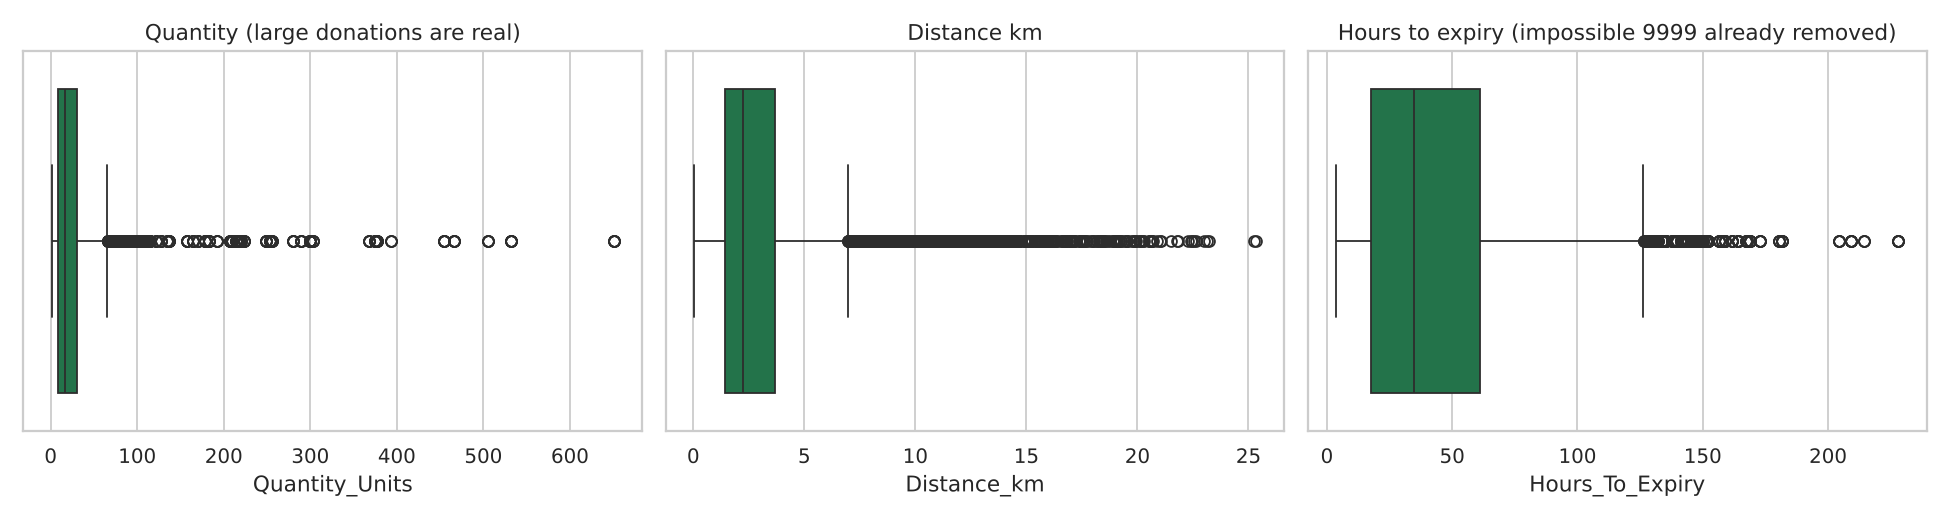

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.boxplot(x=df.Quantity_Units, ax=ax[0]); ax[0].set_title('Quantity (large donations are real)')
sns.boxplot(x=df.Distance_km, ax=ax[1]); ax[1].set_title('Distance km')
sns.boxplot(x=df.Hours_To_Expiry, ax=ax[2]); ax[2].set_title('Hours to expiry (impossible 9999 already removed)')
save(fig, 'outliers')

Impossible values (negative distance, 9999 h expiry, capacity above daily capacity, acceptance rate entered as %) were already fixed. Remaining large values are **real** (big donations, far organizations) and are kept; `Quantity_Log` and scaling reduce their influence for linear/distance models.

## 7. Data splitting (before any statistics are learned)
Chronological 70/15/15 by date. All candidate offers of one donation share its date, so a donation never appears in two splits.

In [11]:
train, val, test = P.chronological_split(df)
for n, s in [('train', train), ('validation', val), ('test', test)]:
    print(f'{n:<11} {len(s):>5} rows {s.Donation_ID.nunique():>5} donations  {s.Date.min().date()} → {s.Date.max().date()}  success rate {s.Successful_Match.mean():.1%}')
art = P.fit_artifacts(train)

train        8505 rows  1732 donations  2025-01-01 → 2025-09-12  success rate 40.6%
validation   1959 rows   404 donations  2025-09-13 → 2025-11-06  success rate 41.0%
test         1808 rows   364 donations  2025-11-07 → 2025-12-31  success rate 40.7%


## 8. Feature engineering
| Feature | Meaning |
|---|---|
| Capacity_Ratio | free capacity ÷ quantity offered |
| Arrival_Hours | hours until open + travel time |
| **Time_Slack_Hours** | hours to expiry − arrival hours (negative = arrives too late) |
| Quantity_Log | log quantity |
| Is_Late_Evening, Is_Weekend | posted after 21:00 / Friday–Saturday |

In [12]:
Xtr, Xva, Xte = (P.build_features(s, art) for s in (train, val, test))
y_tr, y_va, y_te = (s.Successful_Match.astype(int).values for s in (train, val, test))
print(Xtr.shape); Xtr.describe().T.round(2).head(19)

(8505, 36)


,count,mean,std,min,25%,50%,75%,max
Quantity_Units,8505.0,25.29,37.86,1.00,8.00,17.00,31.00,532.00
Quantity_Log,8505.0,2.80,0.98,0.69,2.20,2.89,3.47,6.28
Hours_To_Expiry,8505.0,43.74,33.10,3.60,17.70,33.60,60.30,228.10
Daily_Capacity_Units,8505.0,151.02,98.84,42.00,81.00,131.00,183.00,508.00
Capacity_Remaining_Units,8505.0,79.56,71.21,2.00,32.00,59.00,102.00,507.00
Capacity_Ratio,8505.0,4.71,3.62,0.01,1.50,3.54,9.11,10.00
Past_Acceptance_Rate,8505.0,0.75,0.17,0.26,0.64,0.80,0.87,1.00
Open_Now,8505.0,0.62,0.48,0.00,0.00,1.00,1.00,1.00
Hours_Until_Open,8505.0,4.57,6.10,0.00,0.00,0.00,11.00,17.00
Distance_km,8505.0,3.28,3.10,0.02,1.46,2.27,3.72,25.27


## 9. Encoding
One-hot encoding for Org_Type, Food_Category, Storage_Required and Business_Type; Yes/No → 1/0.

## 10. Feature scaling
StandardScaler fitted on training data, used inside the Logistic Regression and KNN pipelines only.

## 11. Feature selection (mutual information)

Dropped (no information): ['Open_Now', 'Arrival_Hours', 'Posted_Hour']


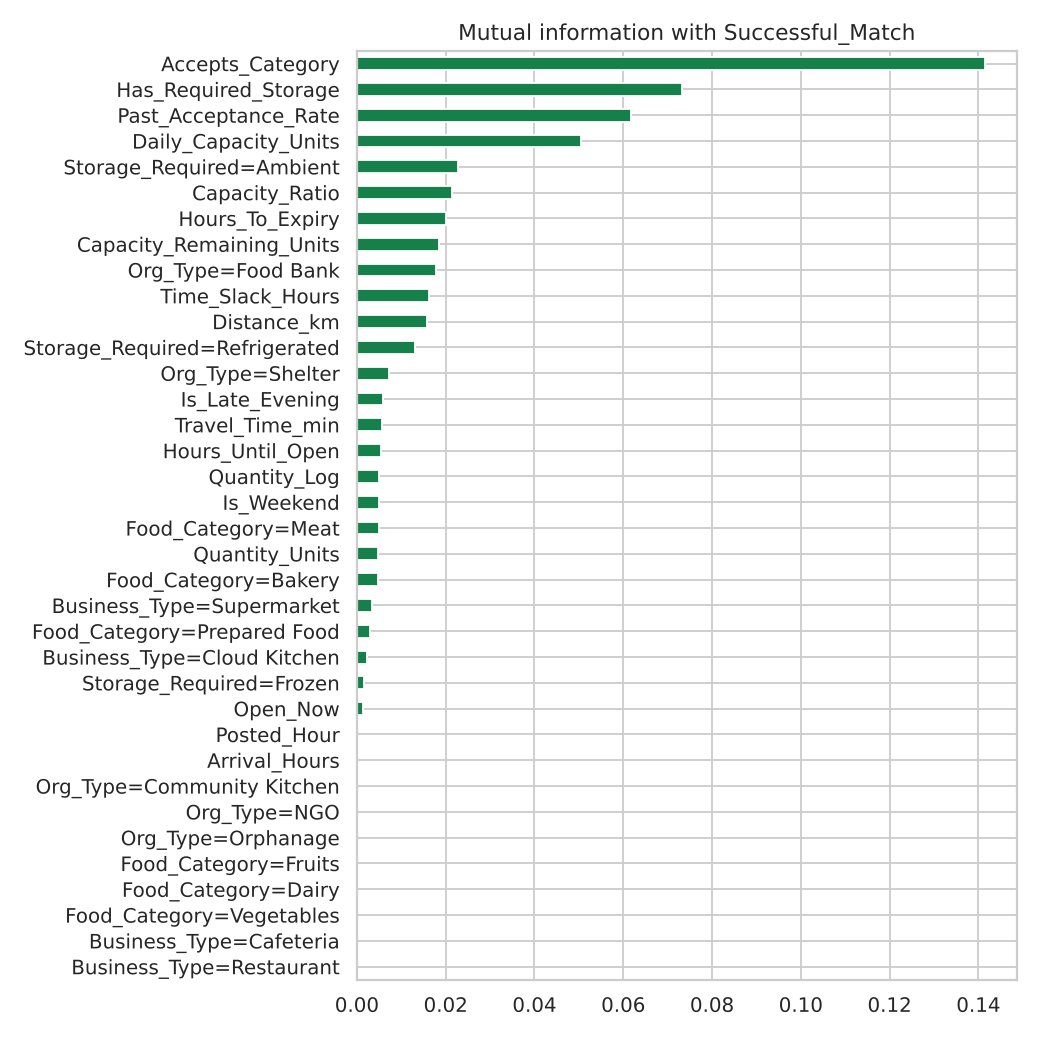

In [13]:
mi = pd.Series(mutual_info_classif(Xtr, y_tr, random_state=RS), index=Xtr.columns).sort_values(ascending=False)
groups = {}
for c in Xtr.columns: groups.setdefault(c.split('=')[0], []).append(c)
FEATURES = [c for g, cols in groups.items() if mi[cols].max() > 0.002 for c in cols]
print('Dropped (no information):', [c for c in Xtr.columns if c not in FEATURES] or 'none')
fig, ax = plt.subplots(figsize=(8, 8)); mi.plot.barh(ax=ax, color='#16804a'); ax.invert_yaxis(); ax.set_title('Mutual information with Successful_Match')
save(fig, 'feature_mutual_information')
Xtr, Xva, Xte = Xtr[FEATURES], Xva[FEATURES], Xte[FEATURES]

## 12. Handling imbalanced data
Success is 41% vs failure 59% (mild imbalance). We compare no balancing, class weights and SMOTE on the validation set (F1 of the *success* class). Tie-break (decided in advance): if strategies are within 0.005 F1, prefer the one with higher recall.

In [14]:
def fit_clf(model, X, y, strategy):
    if strategy == 'smote':
        X, y = SMOTE(random_state=RS).fit_resample(X, y); return model.fit(X, y)
    if strategy == 'balanced':
        key = 'model__sample_weight' if isinstance(model, Pipeline) else 'sample_weight'
        return model.fit(X, y, **{key: compute_sample_weight('balanced', y)})
    return model.fit(X, y)
rows = []
for name, mk in [('Logistic Regression', lambda: Pipeline([('scaler', StandardScaler()), ('model', LogisticRegression(max_iter=3000))])),
                 ('Gradient Boosting', lambda: GradientBoostingClassifier(random_state=RS))]:
    for st in ['none', 'balanced', 'smote']:
        m = fit_clf(mk(), Xtr, y_tr, st); p = m.predict(Xva)
        rows.append({'model': name, 'strategy': st, 'val_F1': f1_score(y_va, p), 'val_recall': recall_score(y_va, p), 'val_accuracy': accuracy_score(y_va, p)})
imb = pd.DataFrame(rows).round(3)
agg = imb.groupby('strategy')[['val_F1', 'val_recall']].mean()
top = agg.val_F1.max(); cand = agg[agg.val_F1 >= top - 0.005]
best_strategy = cand.val_recall.idxmax(); print('Chosen strategy:', best_strategy); imb

Chosen strategy: balanced


,model,strategy,val_F1,val_recall,val_accuracy
0,Logistic Regression,none,0.763,0.824,0.790
1,Logistic Regression,balanced,0.764,0.864,0.781
2,Logistic Regression,smote,0.764,0.861,0.782
3,Gradient Boosting,none,0.770,0.807,0.802
4,Gradient Boosting,balanced,0.771,0.843,0.794
5,Gradient Boosting,smote,0.778,0.829,0.806


## 13. Dimensionality reduction (optional)

In [15]:
rows = []
for name, mdl in [('Logistic Regression', LogisticRegression(max_iter=3000)), ('KNN', KNeighborsClassifier(15))]:
    for use_pca in [False, True]:
        steps = [('scaler', StandardScaler())] + ([('pca', PCA(0.95, random_state=RS))] if use_pca else []) + [('model', mdl)]
        m = Pipeline(steps).fit(Xtr, y_tr); rows.append({'model': name, 'PCA': use_pca, 'val_F1': round(f1_score(y_va, m.predict(Xva)), 3)})
pd.DataFrame(rows)

,model,PCA,val_F1
0,Logistic Regression,False,0.763
1,Logistic Regression,True,0.737
2,KNN,False,0.703
3,KNN,True,0.701


PCA is **not used** in the final model (no clear gain and less explainable).

## 14. Model training & tuning
The app **ranks** organizations by predicted probability, so models are selected on validation **ROC-AUC** (ranking quality). F1, precision and recall are reported too.

In [16]:
grids = {
  'Logistic Regression': [Pipeline([('scaler', StandardScaler()), ('model', LogisticRegression(C=c, max_iter=3000))]) for c in [0.1, 1, 10]],
  'KNN': [Pipeline([('scaler', StandardScaler()), ('model', KNeighborsClassifier(n_neighbors=k, weights=w))]) for k in [7, 15, 31] for w in ['uniform', 'distance']],
  'Decision Tree': [DecisionTreeClassifier(max_depth=d, min_samples_leaf=l, random_state=RS) for d in [4, 6, 8] for l in [10, 30]],
  'Random Forest': [RandomForestClassifier(n_estimators=200, max_depth=d, min_samples_leaf=l, random_state=RS, n_jobs=-1) for d in [8, 12] for l in [3, 10]],
  'Gradient Boosting': [GradientBoostingClassifier(n_estimators=n, max_depth=d, learning_rate=lr, subsample=0.8, random_state=RS) for n in [150, 300] for d in [2, 3] for lr in [0.05, 0.1]],
}
strat_for = lambda name: 'smote' if (name == 'KNN' and best_strategy == 'balanced') else best_strategy
rows, best_models = [], {}
rows.append({'model': 'Baseline (always "No")', 'val_accuracy': accuracy_score(y_va, np.zeros_like(y_va)), 'val_F1': 0.0, 'val_roc_auc': 0.5, 'params': '-'})
for name, cands in grids.items():
    best = None
    for m in cands:
        fit_clf(m, Xtr, y_tr, strat_for(name)); p = m.predict(Xva); auc = roc_auc_score(y_va, m.predict_proba(Xva)[:, 1])
        if best is None or auc > best[3]: best = (f1_score(y_va, p), m, accuracy_score(y_va, p), auc)
    best_models[name] = best[1]
    est = best[1].named_steps['model'] if isinstance(best[1], Pipeline) else best[1]
    params = {k: v for k, v in est.get_params().items() if k in ('C', 'n_neighbors', 'weights', 'max_depth', 'min_samples_leaf', 'n_estimators', 'learning_rate')}
    rows.append({'model': name, 'val_accuracy': best[2], 'val_F1': best[0], 'val_roc_auc': best[3], 'params': str(params)})
val_tbl = pd.DataFrame(rows).round(3).sort_values('val_roc_auc', ascending=False)
BEST = val_tbl[~val_tbl.model.str.startswith('Baseline')].iloc[0]['model']; print('Selected:', BEST); val_tbl

Selected: Gradient Boosting


,model,val_accuracy,val_F1,val_roc_auc,params
5,Gradient Boosting,0.800,0.777,0.872,"{'learning_rate': 0.05, 'max_depth': 3, 'min_s..."
4,Random Forest,0.800,0.777,0.866,"{'max_depth': 12, 'min_samples_leaf': 3, 'n_es..."
3,Decision Tree,0.797,0.772,0.858,"{'max_depth': 8, 'min_samples_leaf': 30}"
1,Logistic Regression,0.781,0.763,0.850,{'C': 0.1}
2,KNN,0.744,0.736,0.824,"{'n_neighbors': 31, 'weights': 'distance'}"
0,"Baseline (always ""No"")",0.590,0.000,0.500,-


## 15. Final evaluation on the unseen test set
Re-train the selected model on train + validation, then evaluate once on the test period.

In [17]:
trval = pd.concat([train, val]); art_final = P.fit_artifacts(trval)
Xtv, Xte_f = P.build_features(trval, art_final)[FEATURES], P.build_features(test, art_final)[FEATURES]
y_tv = trval.Successful_Match.astype(int).values
final = fit_clf(clone(best_models[BEST]), Xtv, y_tv, strat_for(BEST))
proba = final.predict_proba(Xte_f)[:, 1]; pred = (proba >= 0.5).astype(int)
metrics = {'accuracy': accuracy_score(y_te, pred), 'precision': precision_score(y_te, pred), 'recall': recall_score(y_te, pred), 'f1': f1_score(y_te, pred),
           'roc_auc': roc_auc_score(y_te, proba), 'baseline_accuracy': float(np.mean(y_te == 0))}
print(json.dumps({k: round(v, 3) for k, v in metrics.items()}, indent=2))
print(classification_report(y_te, pred, target_names=['Not successful', 'Successful'], digits=3))

{
  "accuracy": 0.811,
  "precision": 0.733,
  "recall": 0.842,
  "f1": 0.784,
  "roc_auc": 0.877,
  "baseline_accuracy": 0.593
}
                precision    recall  f1-score   support

Not successful      0.880     0.790     0.833      1073
    Successful      0.733     0.842     0.784       735

      accuracy                          0.811      1808
     macro avg      0.807     0.816     0.808      1808
  weighted avg      0.820     0.811     0.813      1808



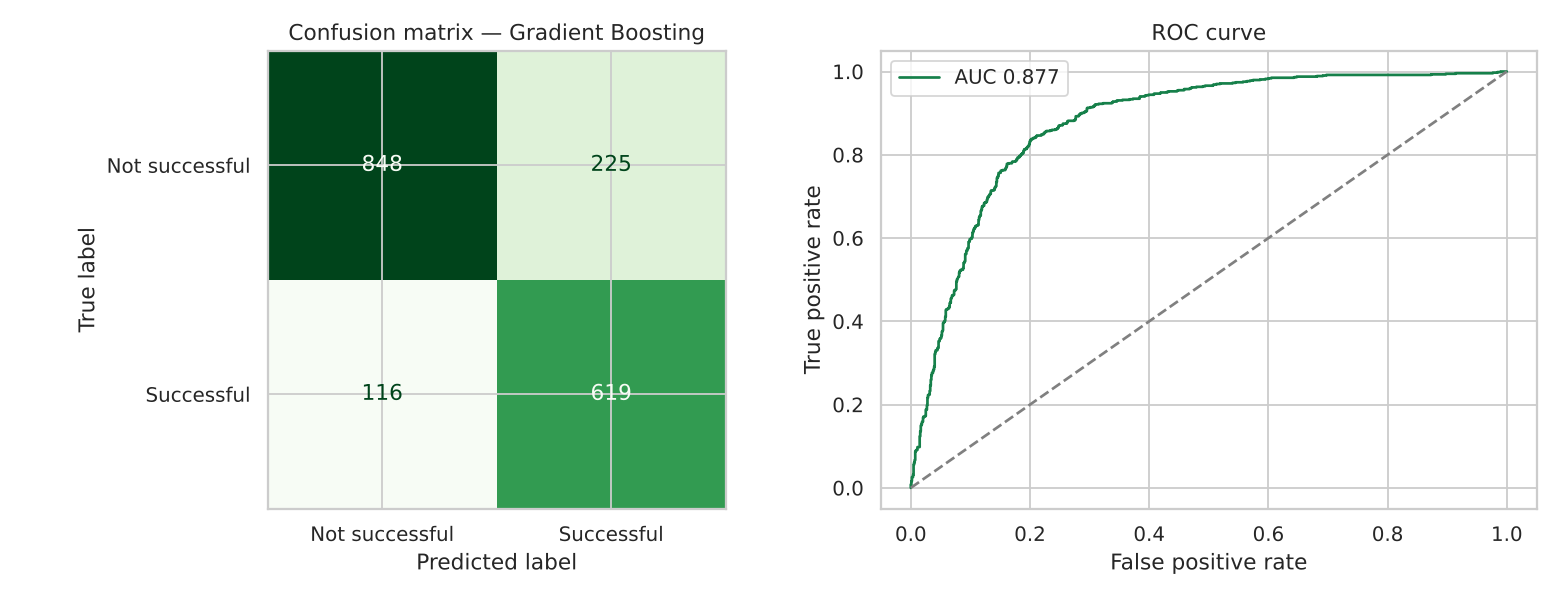

In [18]:
cm = confusion_matrix(y_te, pred)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
ConfusionMatrixDisplay(cm, display_labels=['Not successful', 'Successful']).plot(ax=ax[0], cmap='Greens', colorbar=False); ax[0].set_title(f'Confusion matrix — {BEST}')
fpr, tpr, _ = roc_curve(y_te, proba); ax[1].plot(fpr, tpr, color='#16804a', label=f'AUC {metrics["roc_auc"]:.3f}'); ax[1].plot([0, 1], [0, 1], '--', color='gray')
ax[1].set_xlabel('False positive rate'); ax[1].set_ylabel('True positive rate'); ax[1].set_title('ROC curve'); ax[1].legend()
save(fig, 'confusion_matrix_roc_matching')

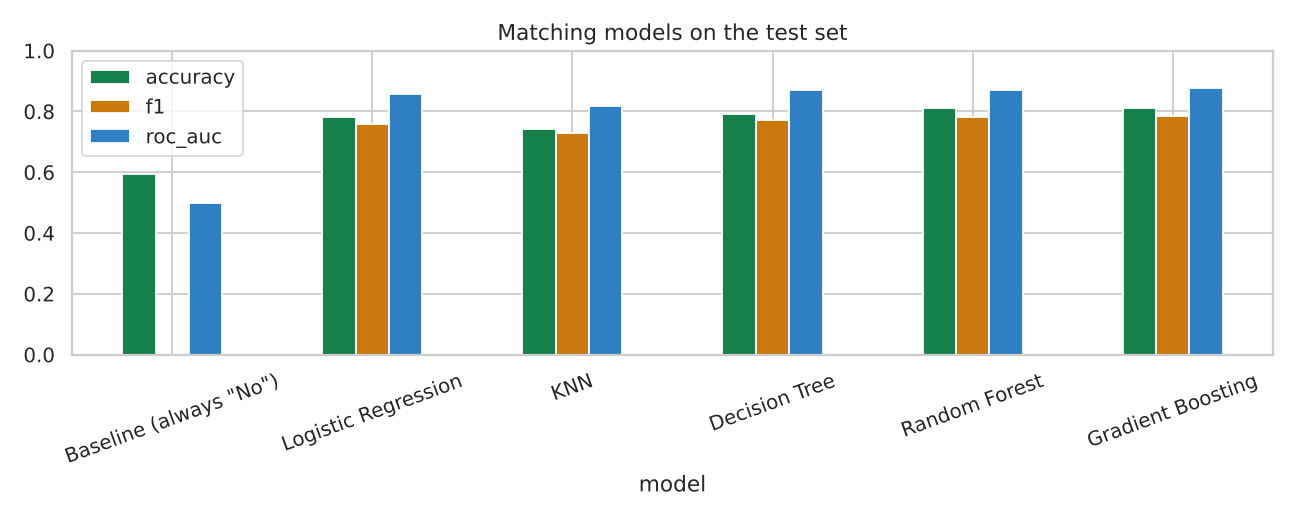

,model,accuracy,precision,recall,f1,roc_auc
0,"Baseline (always ""No"")",0.593,0.000,0.000,0.000,0.500
1,Logistic Regression,0.781,0.688,0.844,0.758,0.856
2,KNN,0.744,0.640,0.848,0.730,0.818
3,Decision Tree,0.793,0.700,0.859,0.771,0.871
4,Random Forest,0.810,0.732,0.841,0.783,0.872
5,Gradient Boosting,0.811,0.733,0.842,0.784,0.877


In [19]:
rows = [{'model': 'Baseline (always "No")', 'accuracy': metrics['baseline_accuracy'], 'precision': 0.0, 'recall': 0.0, 'f1': 0.0, 'roc_auc': 0.5}]
for name, m in best_models.items():
    mm = fit_clf(clone(m), Xtv, y_tv, strat_for(name)); pr = mm.predict_proba(Xte_f)[:, 1]; pp = (pr >= .5).astype(int)
    rows.append({'model': name, 'accuracy': accuracy_score(y_te, pp), 'precision': precision_score(y_te, pp), 'recall': recall_score(y_te, pp), 'f1': f1_score(y_te, pp), 'roc_auc': roc_auc_score(y_te, pr)})
test_tbl = pd.DataFrame(rows).round(3)
fig, ax = plt.subplots(figsize=(10, 4)); test_tbl.set_index('model')[['accuracy', 'f1', 'roc_auc']].plot.bar(ax=ax, rot=20); ax.set_ylim(0, 1); ax.set_title('Matching models on the test set')
save(fig, 'model_comparison_matching'); test_tbl

## 16. Does it pick better organizations? (ranking test — how the app uses the model)
For every test donation, the app removes ineligible organizations (category not accepted / no storage / cannot arrive before expiry)
and then picks the **top-ranked** one. We check how often that top pick was actually a successful match, comparing:
* **AI model** (highest predicted probability)
* **Rule-based score** (the app's previous weighted formula: capacity 30%, distance 30%, timing 20%, need 20%)
* **Nearest organization**
* **Random eligible organization**

In [20]:
t = test.assign(p=proba, y=y_te).reset_index(drop=True)
tf = P.build_features(test, art_final).reset_index(drop=True)
t['eligible'] = (tf.Accepts_Category == 1) & (tf.Has_Required_Storage == 1) & (tf.Time_Slack_Hours > 0)
cap = np.minimum(1, tf.Capacity_Remaining_Units / tf.Quantity_Units); dist = np.clip(1 - tf.Distance_km / 15, 0, 1)
timing = np.clip(tf.Time_Slack_Hours / tf.Hours_To_Expiry, 0, 1); need = np.minimum(1, (tf.Daily_Capacity_Units * 0.5) / tf.Quantity_Units)
t['rule'] = 0.3 * cap + 0.3 * dist + 0.2 * timing + 0.2 * need
t['near'] = -tf.Distance_km
rng = np.random.default_rng(0); t['rand'] = rng.random(len(t))
e = t[t.eligible]
def top1(col): return e.loc[e.groupby('Donation_ID')[col].idxmax(), 'y'].mean()
ranking = pd.DataFrame({'method': ['AI model (top probability)', 'Rule-based weighted score', 'Nearest organization', 'Random eligible organization'],
                        'top_pick_success_rate': [top1('p'), top1('rule'), top1('near'), top1('rand')]}).round(3)
ranking['donations'] = e.Donation_ID.nunique(); ranking

,method,top_pick_success_rate,donations
0,AI model (top probability),0.753,332
1,Rule-based weighted score,0.756,332
2,Nearest organization,0.732,332
3,Random eligible organization,0.702,332


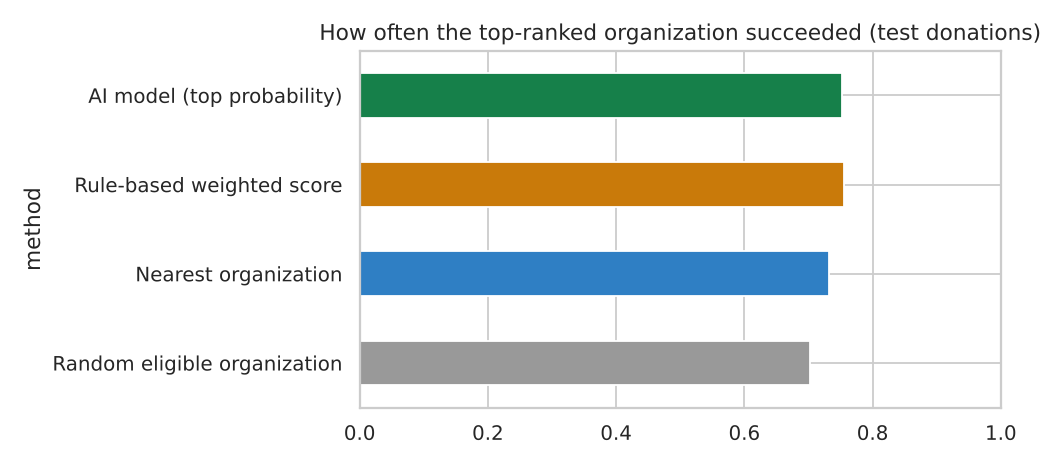

In [21]:
fig, ax = plt.subplots(figsize=(8, 3.6)); ranking.set_index('method').top_pick_success_rate.plot.barh(ax=ax, color=['#16804a', '#c97a0a', '#2f7fc4', '#999999'])
ax.invert_yaxis(); ax.set_xlim(0, 1); ax.set_title('How often the top-ranked organization succeeded (test donations)')
save(fig, 'ranking_top_pick')

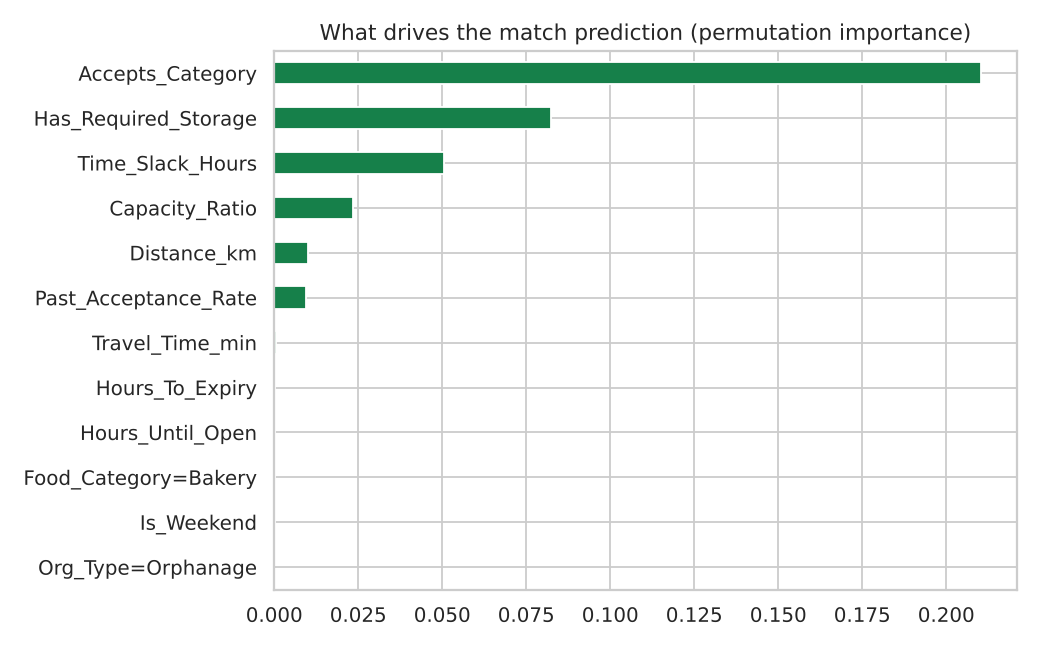

In [22]:
from sklearn.inspection import permutation_importance
pi = permutation_importance(final, Xte_f, y_te, scoring='roc_auc', n_repeats=5, random_state=RS)
imp = pd.Series(pi.importances_mean, index=FEATURES).sort_values(ascending=False).head(12)
fig, ax = plt.subplots(figsize=(8, 5)); imp.plot.barh(ax=ax, color='#16804a'); ax.invert_yaxis(); ax.set_title('What drives the match prediction (permutation importance)')
save(fig, 'feature_importance_matching')

## 17. Save cleaned data, results and the model for the app

In [23]:
df.to_csv('data/processed/matching_cleaned.csv', index=False)
for n, s in [('train', train), ('validation', val), ('test', test)]: s.to_csv(f'data/processed/{n}.csv', index=False)
import sys; sys.path.insert(0, '..')
from common.export import export_model
from datetime import datetime, timezone
bundle = {
  'version': 'match-v1.' + datetime.now(timezone.utc).strftime('%Y%m%d'), 'trained_at': datetime.now(timezone.utc).isoformat(timespec='seconds'),
  'synthetic': True, 'dataset': {'name': 'SYNTHETIC donation-matching dataset (generate_matching_dataset.py)', 'rows_raw': int(len(raw)), 'rows_clean': int(len(df)),
  'donations': int(df.Donation_ID.nunique()), 'organizations': int(df.Org_ID.nunique()), 'success_rate': float(df.Successful_Match.mean())},
  'cleaning': clean_report, 'leakage_columns_removed': P.LEAKAGE_COLUMNS, 'artifacts': {k: v for k, v in art_final.items() if not k.endswith('_by_org')},
  'features': FEATURES, 'algorithm': BEST, 'imbalance_strategy': strat_for(BEST), 'model': export_model(final, Xtv.values[:5]),
  'test': metrics, 'confusion_matrix': cm.tolist(), 'labels': ['Not successful', 'Successful'], 'comparison_test': test_tbl.to_dict('records'),
  'comparison_val': val_tbl.to_dict('records'), 'imbalance_comparison': imb.to_dict('records'), 'ranking_test': ranking.to_dict('records'),
  'feature_importance': imp.round(4).to_dict(),
}
json.dump(bundle, open('../../lib/model/matching-model.json', 'w'), separators=(',', ':'), default=float)
g = test.sample(30, random_state=2)
gold = [{'food_category': r.Food_Category, 'business_type': r.Business_Type, 'org_type': r.Org_Type, 'storage_required': r.Storage_Required,
         'quantity_units': float(r.Quantity_Units), 'hours_to_expiry': None if pd.isna(r.Hours_To_Expiry) else float(r.Hours_To_Expiry),
         'daily_capacity_units': float(r.Daily_Capacity_Units), 'capacity_remaining_units': None if pd.isna(r.Capacity_Remaining_Units) else float(r.Capacity_Remaining_Units),
         'past_acceptance_rate': None if pd.isna(r.Past_Acceptance_Rate) else float(r.Past_Acceptance_Rate), 'open_now': int(r.Open_At_Post_Time),
         'hours_until_open': float(r.Hours_Until_Open), 'distance_km': None if pd.isna(r.Distance_km) else float(r.Distance_km),
         'travel_time_min': None if pd.isna(r.Est_Travel_Time_min) else float(r.Est_Travel_Time_min), 'accepts_category': int(r.Accepts_Category),
         'has_required_storage': int(r.Has_Required_Storage), 'posted_hour': int(r.Posted_Hour), 'day_of_week': int(r.Date.dayofweek)} for r in g.itertuples()]
gX = P.build_features(g.drop(columns=['Org_ID']), art_final)[FEATURES]
json.dump({'inputs': gold, 'features': gX.round(6).values.tolist(), 'proba': final.predict_proba(gX)[:, 1].round(6).tolist()}, open('../../lib/model/matching-golden.json', 'w'))
summary = {'selected': BEST, 'test': {k: round(v, 3) for k, v in metrics.items()}, 'ranking_top_pick': ranking.set_index('method').top_pick_success_rate.to_dict()}
json.dump(summary, open('reports/metrics_summary.json', 'w'), indent=2); print(json.dumps(summary, indent=2))

{
  "selected": "Gradient Boosting",
  "test": {
    "accuracy": 0.811,
    "precision": 0.733,
    "recall": 0.842,
    "f1": 0.784,
    "roc_auc": 0.877,
    "baseline_accuracy": 0.593
  },
  "ranking_top_pick": {
    "AI model (top probability)": 0.753,
    "Rule-based weighted score": 0.756,
    "Nearest organization": 0.732,
    "Random eligible organization": 0.702
  }
}


## 18. Conclusion
* The synthetic dataset needed the full preprocessing pipeline: duplicates, inconsistent text, mixed formats, units inside numbers, impossible values and missing data.
* The selected model ranks organizations; in the app it runs **after** safety rules remove impossible matches.
* **Limitation (must be stated):** the data is simulated, so the model can only learn the patterns that were simulated. Real accuracy requires re-training on real platform outcomes, which the app already records.